# Inference-time self-improvement with Gumbeldore sampling

Notebook 01 sampled a pool of candidates once, then filtered it. Rejected molecules taught the model nothing.

Gumbeldore closes that loop at inference time, with no gradient steps:

1. Sample distinct sequences with stochastic beam search (SBS) — Gumbel noise on
   the log-probabilities turns a beam search into an exact sample without replacement.
2. Score each finished sequence; here, the distance of its logP from a target.
3. Shift the log-probabilities *in the search tree* towards branches that scored above expectation, then sample the
   next round from the updated tree.

The budget is the same 100 molecules as notebook 01.

## Setup

Run this cell first, then run the rest of the notebook top to bottom. It clones the repository, installs the
package and downloads the model checkpoints. It takes about a minute and only needs to run once per session.

In [137]:
# Setup: clone the repository, install the package, download the checkpoints
import importlib
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/szczurek-lab/mlinpl-jsi.git"
CKPT_FOLDER_URL = "https://drive.google.com/drive/folders/1yG0Qp3sVtrY_chM5L78V6QyfYjgX9CLl"


def pip_run(*args: str) -> None:
    subprocess.check_call([sys.executable, "-m", *args])


if not Path("../configs").is_dir():  # not inside the repository yet
    if not Path("mlinpl-jsi").is_dir():
        subprocess.check_call(["git", "clone", "--depth", "1", REPO_URL])
    # Colab already ships torch, numpy, pandas and scikit-learn.
    # --no-deps keeps those versions instead of reinstalling a multi-gigabyte torch.
    pip_run("pip", "install", "-q", "rdkit", "loguru", "gdown")
    pip_run("pip", "install", "-q", "--no-deps", "-e", "mlinpl-jsi")
    os.chdir("mlinpl-jsi/notebooks")  # every path below is relative to REPO_ROOT = cwd.parent

# An editable install registers itself through a .pth file, which Python only reads when it starts up.
# This kernel is already running, so point it at the sources directly instead of restarting the runtime.
src_path = str(Path("../src").resolve())
if src_path not in sys.path:
    sys.path.insert(0, src_path)
importlib.invalidate_caches()

# The checkpoints are distributed over Google Drive, not in the repository
if not Path("../model_ckpt/model_finetuned.pt").exists():
    pip_run("gdown", "--folder", "--quiet", CKPT_FOLDER_URL, "-O", "../model_ckpt")

import joint_improvement  # noqa: E402
import torch  # noqa: E402

print(f"working directory: {Path.cwd()}")
print(f"joint_improvement: {joint_improvement.__file__}")
print(f"torch {torch.__version__}, cuda available: {torch.cuda.is_available()}")
print("Setup finished. Continue to the next cell.")

working directory: /content/mlinpl-jsi/notebooks
joint_improvement: /content/mlinpl-jsi/src/joint_improvement/__init__.py
torch 2.11.0+cu130, cuda available: True
Setup finished. Continue to the next cell.


In [138]:
# Imports and repo root

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Draw

from joint_improvement.generators.utils.linear_scheduler import LinearScheduler
from joint_improvement.hyformer import Hyformer, HyformerConfig
from joint_improvement.tokenizers import SMILESTokenizer
from joint_improvement.utils.chemistry import calculate_logp, calculate_validity
from joint_improvement.utils.data.collators import PredictionCollator

REPO_ROOT = Path.cwd().parent  # notebook is run from notebooks/

In [139]:
# Set the device and run a quick installation check: repo root, torch/device, and a logP sanity value for ethanol
device = "cuda" if torch.cuda.is_available() else "cpu"

assert (REPO_ROOT / "configs").is_dir(), f"REPO_ROOT looks wrong: {REPO_ROOT}"
print(f"torch {torch.__version__}, device: {device}")
print(f"logP(ethanol) = {calculate_logp('CCO'):.4f}")

torch 2.11.0+cu130, device: cuda
logP(ethanol) = -0.0014


## Load Hyformer with the Inference-time self-improvement

`generator_type` decides which `generate()` is mixed into the model class. Notebook 01 used `unconditional`;
`configs/hyformer/gumbeldore_sampling.json` asks for `gumbeldore` — Self-improvement with advantage updates. That config also
declares the logP regression head, so the model both proposes and scores.

`model_ckpt/model_finetuned.pt` is jointly finetuned as LM + logP regressor, equivalent to what notebook 01 saves.

In [140]:
# Define the constants of this section
TOKENIZER_CONFIG_PATH = REPO_ROOT / "configs/tokenizers/smiles/zinc250k/tokenizer_config.json"
VOCAB_PATH = REPO_ROOT / "data/vocabularies/zinc250k.txt"
MODEL_CONFIG_PATH = REPO_ROOT / "configs/hyformer/gumbeldore_sampling.json"  # must match the checkpoint below

FINETUNED_CKPT_PATH = REPO_ROOT / "model_ckpt/model_finetuned.pt"  # jointly finetuned for LM + logP regression

In [141]:
# Load the tokenizer and the finetuned model, this time with the Gumbeldore sampler mixed in
assert FINETUNED_CKPT_PATH.exists(), f"Set FINETUNED_CKPT_PATH to a finetuned checkpoint, got {FINETUNED_CKPT_PATH!r}"

tokenizer = SMILESTokenizer.from_pretrained(TOKENIZER_CONFIG_PATH, vocab_filepath=VOCAB_PATH)

config = HyformerConfig.from_pretrained(MODEL_CONFIG_PATH)
model = Hyformer.from_config(config).to(device).eval()  # generator_type="gumbeldore" picks the sampler
model.load_pretrained(FINETUNED_CKPT_PATH, device=device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Number of parameters: {n_params:,} ({n_params / 1e6:.2f}M)")
print(f"sampler: Inference-time self-improvement")

2026-10-10 15:40:26.188 | INFO     | joint_improvement.hyformer.pretrained:load_pretrained:114 - Loaded weights from /content/mlinpl-jsi/model_ckpt/model_finetuned.pt


Number of parameters: 6,839,041 (6.84M)
sampler: Inference-time self-improvement


[link text](https://)## The task: hit a target logP

Same target as notebook 01, the 95th percentile of ZINC250k. Hyformer proposes with its LM head and scores with its
regression head — no external oracle.

We need two functions:

- `oracle_fn(state)` scores a finished sequence; ours decodes the SMILES and runs the regression head.
- `advantage_fn(score)` is **maximized**: `-|score - target|`, so 0 is a perfect hit.

Unparseable SMILES get a large negative advantage, so invalid branches lose probability mass.

In [142]:
# Define the objective: the model's own logP prediction as the oracle, negative distance to the target as the advantage
TARGET_LOGP = 4.54  # the 95th percentile of the ZINC250k logP distribution, as computed in notebook 01
EPSILON = 0.5  # rejection sampling accepts a molecule if |predicted logP - target| <= EPSILON
INVALID_ADVANTAGE = -10.0  # advantage of a sequence that does not decode to a valid molecule

PREFIX_IDS = [tokenizer.task_token_ids["lm"], tokenizer.bos_token_id]  # every sequence starts with [<lm>, <bos>]
collator = PredictionCollator(tokenizer, max_length=config.max_seq_len)


def decode_state(state: torch.Tensor) -> str:
    """Decode one generated token-id sequence (prefix included) into a SMILES string."""
    ids = state.tolist()[len(PREFIX_IDS) :]
    if tokenizer.eos_token_id in ids:  # sequences that finished early keep sampling, so cut at the first <eos>
        ids = ids[: ids.index(tokenizer.eos_token_id)]
    return tokenizer.decode(ids)


def predict_logp(smiles: list[str]) -> np.ndarray:
    """Return the Hyformer-predicted logP of each SMILES."""
    batch = collator([{"sequence": s} for s in smiles])
    with torch.inference_mode():
        predictions = model.predict(batch.input_ids.to(device), batch.attention_mask.to(device))
    return predictions.squeeze(-1).cpu().numpy()


def oracle_fn(state: torch.Tensor) -> float:
    """Score a finished sequence with the model's logP prediction; NaN marks a molecule RDKit cannot parse."""
    smiles = decode_state(state)
    if not smiles or not calculate_validity(smiles):
        return float("nan")
    return float(predict_logp([smiles])[0])


def advantage_fn(score: float) -> float:
    """Maximized by the search: 0 for a molecule exactly on target, more negative the further away it is."""
    if np.isnan(score):
        return INVALID_ADVANTAGE
    return -abs(score - TARGET_LOGP)


print(f"Target logP: {TARGET_LOGP:.2f} (epsilon={EPSILON})")

Target logP: 4.54 (epsilon=0.5)


## Gumbeldore sampling

One `generate()` call runs `NUM_ROUNDS` rounds of SBS at width `BEAM_WIDTH`, returning 100 distinct sequences.

- `advantage_constant` (σ) is the step size
- `return_full_info=True` also returns each sequence's round.

In [132]:
# Gumbeldore sampling: NUM_ROUNDS rounds of Self-improvement, updating the search tree's log-probs after each round
BEAM_WIDTH = 25  # distinct sequences sampled per round
NUM_ROUNDS = 4  # BEAM_WIDTH * NUM_ROUNDS = 100 finished sequences, matching notebook 01's budget

# Sampling hyperparameters
TEMPERATURE = 0.9  # <1 = more conservative samples, >1 = more diverse
TOP_K = 25  # sample only from the k most likely tokens (0 or None = off)
SEED = 0  # seed of the sampling random number generator
ADVANTAGE_CONSTANT = 1.75  # sigma, step size
MIN_NUCLEUS_TOP_P = 1.0  # keeps the full nucleus (no truncation) when updating the tree

gumbeldore_states, round_info = model.generate(
    prefix_input_ids=torch.tensor(PREFIX_IDS, device=device),  # a single prefix, not a batch
    max_sequence_length=config.max_seq_len,  # this generate() counts the prefix too
    advantage_fn=advantage_fn,
    eos_token_id=tokenizer.eos_token_id,
    oracle_fn=oracle_fn,
    temperature=TEMPERATURE,
    top_k=TOP_K,
    beam_width=BEAM_WIDTH,
    num_rounds=NUM_ROUNDS,
    log_prob_update_type="gumbeldore",
    advantage_constant=ADVANTAGE_CONSTANT,
    normalize_advantage_value=True,  # min-max normalize advantages to [-1, 1] within a round
    min_nucleus_top_p=MIN_NUCLEUS_TOP_P,
    rng=np.random.default_rng(SEED),
    return_full_info=True,
)

gumbeldore_smiles = [decode_state(state) for state in gumbeldore_states]
gumbeldore_rounds = np.array(round_info["round_idx"])
print(f"gumbeldore: {len(gumbeldore_smiles)} sequences over {gumbeldore_rounds.max() + 1} rounds")
print(f"unique SMILES: {len(set(gumbeldore_smiles))} (Self-improvement samples without replacement within a round)")

gumbeldore: 100 sequences over 4 rounds
unique SMILES: 100 (Self-improvement samples without replacement within a round)


## Evaluation

Selection uses predicted logP, evaluation uses RDKit. `hit` is the fraction whose *true* logP falls within
`EPSILON` of the target, counted against the full pool, so it is comparable to notebook 01's acceptance rate.

Round 0 is drawn before any update, so round 0 against the last round is what the feedback bought.

In [133]:
# Evaluate Gumbeldore on the true (RDKit) logP: the whole pool, then round by round
def evaluate(smiles_list: list[str], target: float, epsilon: float) -> dict[str, float]:
    """Return the validity and hit rate of `smiles_list` and, over its valid molecules, the mean absolute
    deviation of the RDKit logP from `target` and the standard deviation of the RDKit logP."""
    valid = [s for s in smiles_list if calculate_validity(s)]
    logp = np.array([calculate_logp(s) for s in valid])
    return {
        "validity": len(valid) / len(smiles_list) if smiles_list else 0.0,
        # a hit is counted against the full pool, so invalid molecules count as misses
        "hit": float((np.abs(logp - target) <= epsilon).sum() / len(smiles_list)) if smiles_list else 0.0,
        "mad": float(np.abs(logp - target).mean()) if valid else float("nan"),
        "std": float(logp.std()) if valid else float("nan"),
    }


pools = {"all rounds": gumbeldore_smiles} | {
    f"round {r}": [s for s, round_idx in zip(gumbeldore_smiles, gumbeldore_rounds) if round_idx == r]
    for r in range(NUM_ROUNDS)
}

for name, smiles_list in pools.items():
    metrics = evaluate(smiles_list, TARGET_LOGP, EPSILON)
    print(
        f"{name:>11}: n={len(smiles_list):>3}  MAD={metrics['mad']:.3f}  std={metrics['std']:.3f}  "
        f"hit={metrics['hit']:.1%}  validity={metrics['validity']:.1%}"
    )

 all rounds: n=100  MAD=1.717  std=1.094  hit=10.0%  validity=95.0%
    round 0: n= 25  MAD=2.228  std=1.306  hit=8.0%  validity=92.0%
    round 1: n= 25  MAD=1.872  std=1.179  hit=8.0%  validity=96.0%
    round 2: n= 25  MAD=1.512  std=0.824  hit=12.0%  validity=96.0%
    round 3: n= 25  MAD=1.276  std=0.720  hit=12.0%  validity=96.0%


### Improvement across rounds

Left: each molecule's true logP by round, with MAD on its own axis. Right: first round against last.

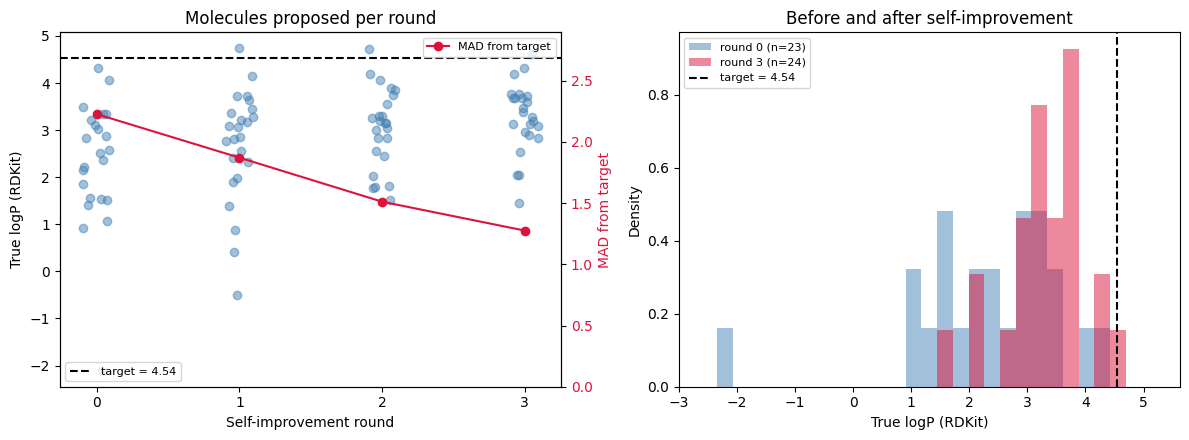

MAD per round: r0=2.228, r1=1.872, r2=1.512, r3=1.276


In [134]:
# Left: true logP per Gumbeldore round vs the target. Right: first round vs last round.
fig, (ax_rounds, ax_dist) = plt.subplots(1, 2, figsize=(12, 4.5))

round_logp = []
for r in range(NUM_ROUNDS):
    valid_r = [s for s in pools[f"round {r}"] if calculate_validity(s)]
    round_logp.append(np.array([calculate_logp(s) for s in valid_r]))
    if valid_r:  # one dot per molecule, jittered so overlapping values stay visible
        jitter = np.random.default_rng(r).uniform(-0.1, 0.1, len(valid_r))
        ax_rounds.scatter(np.full(len(valid_r), r) + jitter, round_logp[r], alpha=0.5, color="steelblue")

ax_rounds.axhline(TARGET_LOGP, color="black", linestyle="--", label=f"target = {TARGET_LOGP:.2f}")
ax_rounds.set_xticks(range(NUM_ROUNDS))
ax_rounds.set_xlabel("Self-improvement round")
ax_rounds.set_ylabel("True logP (RDKit)")
ax_rounds.set_title("Molecules proposed per round")
ax_rounds.legend(fontsize=8, loc="lower left")

# MAD is a distance, not a logP, so it gets its own axis rather than sharing the left one
round_mad = [np.abs(logp - TARGET_LOGP).mean() if len(logp) else np.nan for logp in round_logp]
ax_mad = ax_rounds.twinx()
ax_mad.plot(range(NUM_ROUNDS), round_mad, color="crimson", marker="o", label="MAD from target")
ax_mad.set_ylabel("MAD from target", color="crimson")
ax_mad.tick_params(axis="y", labelcolor="crimson")
ax_mad.set_ylim(0, max(round_mad) * 1.3)
ax_mad.legend(fontsize=8, loc="upper right")

# bin over the range the molecules actually occupy, not the full ZINC250k span
observed = np.concatenate([logp for logp in round_logp if len(logp)])
bins = np.linspace(min(observed.min(), TARGET_LOGP) - 0.5, max(observed.max(), TARGET_LOGP) + 0.5, 30)
for r, color in [(0, "steelblue"), (NUM_ROUNDS - 1, "crimson")]:
    if len(round_logp[r]):  # density=True keeps rounds with different valid counts comparable
        ax_dist.hist(round_logp[r], bins=bins, density=True, alpha=0.5, color=color,
                     label=f"round {r} (n={len(round_logp[r])})")
ax_dist.axvline(TARGET_LOGP, color="black", linestyle="--", label=f"target = {TARGET_LOGP:.2f}")
ax_dist.set_xlabel("True logP (RDKit)")
ax_dist.set_ylabel("Density")
ax_dist.set_title("Before and after self-improvement")
ax_dist.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("MAD per round: " + ", ".join(f"r{r}={mad:.3f}" for r, mad in enumerate(round_mad)))

### Is the search exploiting its own predictor?

True against predicted logP, coloured by round. The search maximizes *predicted* logP, so it can favour molecules
the predictor over-rates: points drifting above `y = x` while staying inside the acceptance band look like hits and
are not. Watch whether mean `|predicted - true|` grows with the rounds.

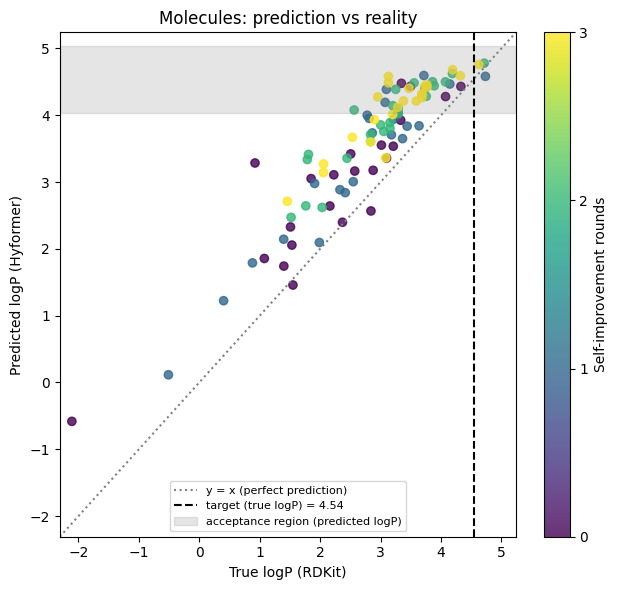

Mean |predicted - true| per round: r0=0.661, r1=0.678, r2=0.824, r3=0.821


In [135]:
# Real (RDKit) vs predicted (Hyformer) logP of every valid molecule, coloured by the round it came from
valid_idx = [i for i, s in enumerate(gumbeldore_smiles) if calculate_validity(s)]  # RDKit cannot score invalid SMILES

if not valid_idx:
    print("No valid molecules to plot")
else:
    valid_smiles = [gumbeldore_smiles[i] for i in valid_idx]
    real_logp = np.array([calculate_logp(s) for s in valid_smiles])
    predicted_logp = predict_logp(valid_smiles)
    rounds_valid = gumbeldore_rounds[valid_idx]
    lims = [
        min(real_logp.min(), predicted_logp.min(), TARGET_LOGP - EPSILON) - 0.2,
        max(real_logp.max(), predicted_logp.max(), TARGET_LOGP + EPSILON) + 0.2,
    ]

    fig, ax = plt.subplots(figsize=(6.5, 6))
    scatter = ax.scatter(real_logp, predicted_logp, c=rounds_valid, cmap="viridis", alpha=0.8,
                         vmin=0, vmax=NUM_ROUNDS - 1)
    ax.plot(lims, lims, color="gray", linestyle=":", label="y = x (perfect prediction)")
    ax.axvline(TARGET_LOGP, color="black", linestyle="--", label=f"target (true logP) = {TARGET_LOGP:.2f}")
    ax.axhspan(TARGET_LOGP - EPSILON, TARGET_LOGP + EPSILON, color="gray", alpha=0.2,
               label="acceptance region (predicted logP)")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("True logP (RDKit)")
    ax.set_ylabel("Predicted logP (Hyformer)")
    ax.set_title("Molecules: prediction vs reality")
    ax.legend(fontsize=8)
    fig.colorbar(scatter, ax=ax, label="Self-improvement rounds", ticks=range(NUM_ROUNDS))
    plt.tight_layout()
    plt.show()

    # Mean prediction error per round: growing values mean the search is drifting towards the predictor's blind spots
    errors = np.abs(predicted_logp - real_logp)
    print("Mean |predicted - true| per round: " + ", ".join(
        f"r{r}={errors[rounds_valid == r].mean():.3f}" if (rounds_valid == r).any() else f"r{r}=n/a"
        for r in range(NUM_ROUNDS)
    ))

true (RDKit)=  4.62  predicted=  4.76  Cc1ccc(NC(=O)CSc2nnc(-c3ccc(F)cc3)n2Cc2ccccc2)cc1


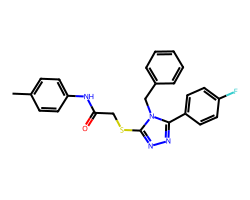

true (RDKit)=  4.71  predicted=  4.78  Cc1ccc(NC(=O)CSc2nnc(-c3ccc(F)cc3)n2Cc2cccs2)cc1


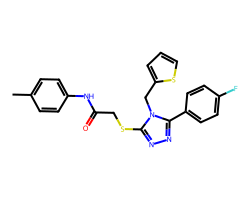

true (RDKit)=  4.73  predicted=  4.58  Cc1ccc(C)c(C(=O)N2CCC[C@H]2c2csc(C)c2C)c1


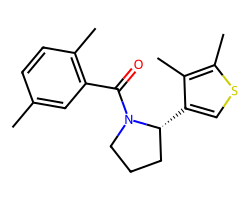

true (RDKit)=  4.33  predicted=  4.43  C[C@@H](NC(=O)N[C@H](C)c1cc(F)ccc1F)c1ccc(Cl)cc1


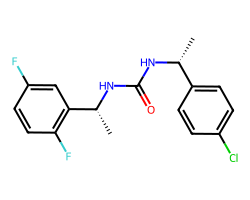

In [136]:
# Draw the molecules closest to the target (true logP), with the model's prediction for comparison
N_TO_PLOT = 4

valid_gumbeldore = [s for s in gumbeldore_smiles if calculate_validity(s)]  # RDKit cannot score invalid SMILES

if not valid_gumbeldore:
    print("No valid molecules to draw")
else:
    true_logp = np.array([calculate_logp(s) for s in valid_gumbeldore])
    best = np.argsort(np.abs(true_logp - TARGET_LOGP))[:N_TO_PLOT]
    predictions = predict_logp([valid_gumbeldore[i] for i in best])

    for i, pred in zip(best, predictions):
        print(f"true (RDKit)={true_logp[i]:6.2f}  predicted={pred:6.2f}  {valid_gumbeldore[i]}")
        display(Draw.MolToImage(Chem.MolFromSmiles(valid_gumbeldore[i]), size=(250, 200)))